In [3]:
import pandas as pd 
df = pd.read_csv(r"netflix_cleaned_dataset.csv")
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [5]:
# check the release year column 
df["release_year"].head()

0    2020
1    2021
2    2021
3    2021
4    1993
Name: release_year, dtype: int64

In [7]:
# group content by release year 

yearly_content = df.groupby('release_year')

yearly_content

In [9]:
# calculate the number of content release for each year 

yearly_content = df.groupby('release_year').size().reset_index(name='content_count')

yearly_content.head()

,release_year,content_count
0,1925,1
1,1942,2
2,1943,3
3,1944,3
4,1945,4


In [11]:
# years with most release 

yearly_content.sort_values('content_count',ascending=False).head(10)

,release_year,content_count
70,2018,1146
69,2017,1030
71,2019,1030
72,2020,953
68,2016,901
73,2021,592
67,2015,555
66,2014,352
65,2013,286
64,2012,236


In [14]:
# find the top 10 release years :
top_years = yearly_content.sort_values('content_count', ascending=False).head(10)
print(top_years)

    release_year  content_count
70          2018           1146
69          2017           1030
71          2019           1030
72          2020            953
68          2016            901
73          2021            592
67          2015            555
66          2014            352
65          2013            286
64          2012            236


In [15]:
lowest_years =  yearly_content.sort_values('content_count', ascending=True).head(10)
print(lowest_years)

    release_year  content_count
0           1925              1
6           1947              1
13          1961              1
11          1959              1
18          1966              1
7           1954              2
5           1946              2
15          1963              2
9           1956              2
17          1965              2


In [19]:
print(yearly_content.columns)

Index(['release_year', 'content_count'], dtype='object')


In [22]:
# Step 1: Sort data by release year
yearly_content = yearly_content.sort_values('release_year').reset_index(drop=True)

# Step 2: Calculate year-wise change in content
yearly_content['yearly_change'] = yearly_content['content_count'].diff()

# Step 3: Find the largest increase
largest_increase = yearly_content.loc[
    yearly_content['yearly_change'].idxmax()
]

# Step 4: Print the result
print(largest_increase)

release_year     2016.0
content_count     901.0
yearly_change     346.0
Name: 68, dtype: float64


In [23]:

# Step 3: Find the largest decline
largest_decline = yearly_content.loc[
    yearly_content['yearly_change'].idxmin()
]

# Step 4: Print the result
print(largest_decline)

release_year     2021.0
content_count     592.0
yearly_change    -361.0
Name: 73, dtype: float64


In [24]:
# visualiation

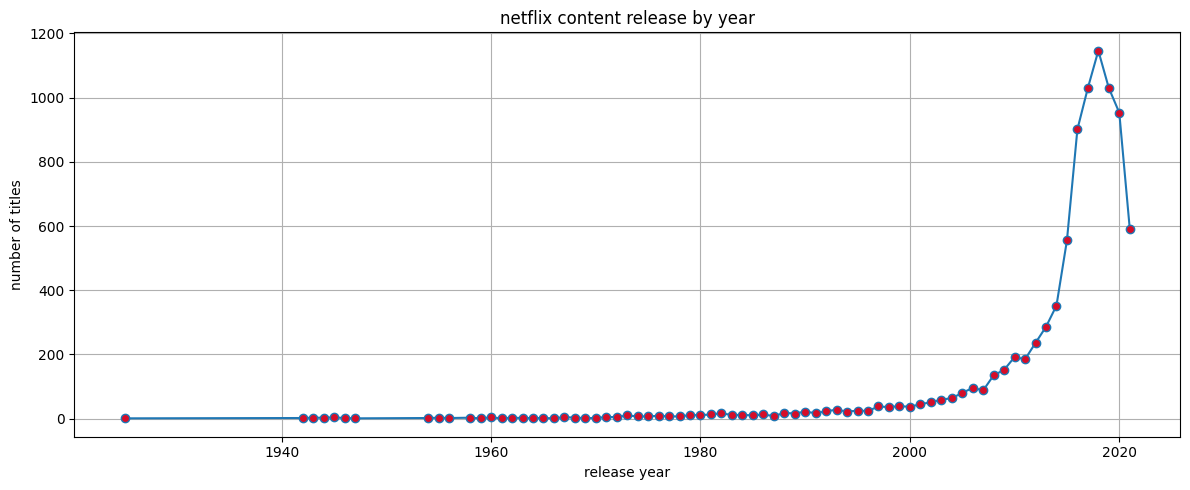

In [28]:
# create the trend chart 
import matplotlib.pyplot as plt 
plt.figure(figsize=(12,5))
plt.plot(yearly_content["release_year"], yearly_content["content_count"],
         marker="o", markerfacecolor="#d60d28")

plt.title("netflix content release by year")
plt.xlabel("release year")
plt.ylabel("number of titles")

plt.grid(True)
plt.tight_layout()
plt.show()

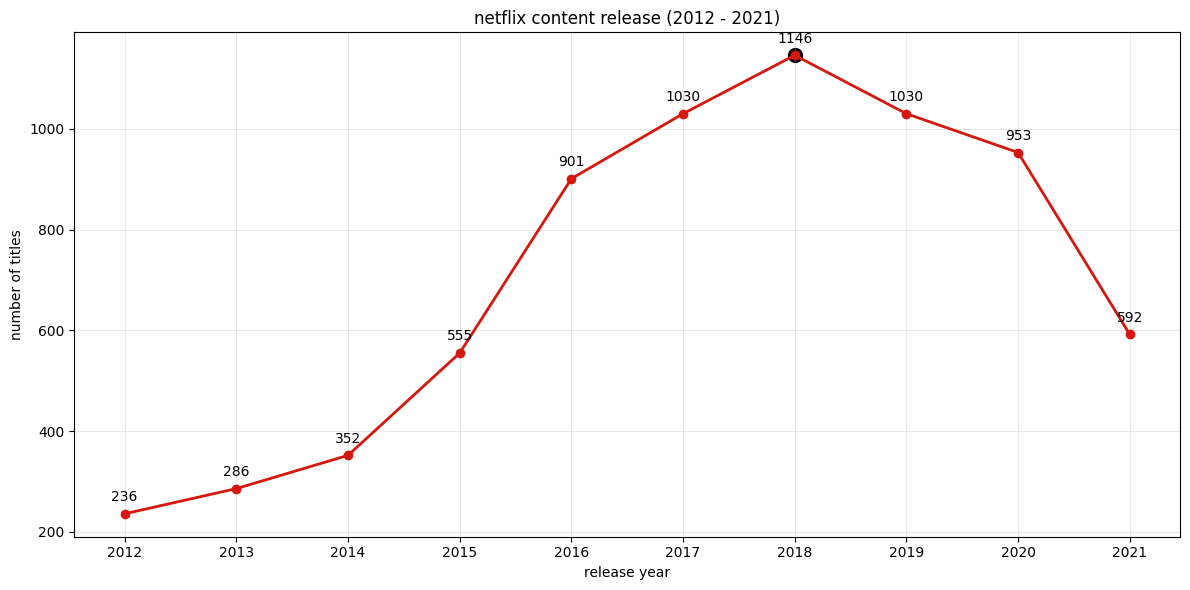

In [31]:
import matplotlib.pyplot as plt
recent_years = yearly_content[(yearly_content["release_year"] >= 2012) & (yearly_content["release_year"] <= 2021)]
plt.figure(figsize=(12,6))


plt.plot(recent_years["release_year"], recent_years["content_count"], marker="o", 
         linewidth=2, color="#d6170d")

for x, y in zip(recent_years["release_year"], recent_years["content_count"]):
    plt.text(x,y+ 25, str(y), ha="center")


peak_year = recent_years.loc[recent_years["content_count"].idxmax()]
plt.scatter(peak_year["release_year"], peak_year["content_count"], 
            s=100, color="#000000")

plt.title("netflix content release (2012 - 2021)")
plt.xlabel("release year")
plt.ylabel("number of titles")
plt.xticks(recent_years["release_year"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Step - 5 Business Insights 